In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, r2_score

import sys
import os
cartella_src = os.path.abspath(os.path.join(os.getcwd(), '..', 'src'))

if cartella_src not in sys.path:
    sys.path.insert(0, cartella_src)
# 1. Importiamo i moduli custom dai file fisici
from Preprocessor import FullPipeline
from Regression.LinearRegression import LinearRegression

# 2. Caricamento e Preprocessing
print("Inizializzazione della FullPipeline...")
path_al_dataset = '../Dataset/AB_NYC_2019.csv'

pipeline = FullPipeline(path_al_dataset)
df_clean = pipeline.transform()
print(f"Dataset pulito. Shape: {df_clean.shape[0]} x {df_clean.shape[1]}")

# 3. Split e Scaling
X = df_clean.drop(columns=['log_price'])
y = df_clean['log_price']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

scaler = StandardScaler()
X_train_scaled = pd.DataFrame(scaler.fit_transform(X_train), columns=X_train.columns)
X_test_scaled = pd.DataFrame(scaler.transform(X_test), columns=X_test.columns)

# 4. Addestramento del Modello (es. Lasso)
print("Addestramento del modello in corso...")
# Puoi testare penalty='l1' (Lasso), penalty='l2' (Ridge), o penalty=None (OLS standard)
model = LinearRegression(penalty='l1', alpha=0.01) 
model.fit(X_train_scaled, y_train)

# 5. Previsione
y_pred_log = model.predict(X_test_scaled)

# 6. Valutazione Economica (riconversione da log a dollari)
y_test_dollars = np.expm1(y_test)
y_pred_dollars = np.expm1(y_pred_log)

rmse = np.sqrt(mean_squared_error(y_test_dollars, y_pred_dollars))
r2 = r2_score(y_test, y_pred_log)

print(f"\n--- Risultati ---")
print(f"R^2 Score: {r2:.4f}")
print(f"RMSE (Errore Medio): ${rmse:.2f}")

# 7. Analisi dei Coefficienti
coef_df = pd.DataFrame({
    'Feature': X_train.columns,
    'Coefficiente': model.coefficients
})

# Filtriamo solo le variabili che la Lasso ha mantenuto attive
driver_attivi = coef_df[coef_df['Coefficiente'] != 0].copy()
driver_attivi['Impatto'] = driver_attivi['Coefficiente'].abs()
driver_attivi = driver_attivi.sort_values(by='Impatto', ascending=False)

print("\n--- Top 10 Primary Drivers ---")
print(driver_attivi[['Feature', 'Coefficiente']].head(10))

Inizializzazione della FullPipeline...
Dataset pulito. Shape: 48869 x 16
Addestramento del modello in corso...

--- Risultati ---
R^2 Score: 0.5054
RMSE (Errore Medio): $103.89

--- Top 10 Primary Drivers ---
                          Feature  Coefficiente
10              room_type_ordinal      0.373994
7            distance_from_center     -0.154683
4                availability_365      0.085615
12  neighbourhood_group_Manhattan      0.077848
0                  minimum_nights     -0.033237
1               number_of_reviews     -0.020326
5            last_review_days_ago     -0.010861
2               reviews_per_month     -0.003652
9            host_is_professional     -0.002000
6              availability_ratio      0.000627


Si nota che la variabile che fa aumentare principalmente il prezzo è il tipo di stanza. Il coefficiente corrispondente è di 0.384798, questo significa che exp(0.384798)-1= 0.468, cioè che questa variabile può far aumentare il prezzo del 46.8%
Un discorso simile lo si applica per neighbourhood_group_Manhattan: lo stare vicino al centro di Manhattan auamenta il prezzo del 17.2%

R^2 è basso per la natura del dataset. Infatti questo non contiene informazioni circa la grandezza delle stanze e i vari servizi offerti con la stanza (piscina, tipologia di arredamento, etc.)


In [3]:
# Importa il nuovo modulo
from Regression.TreeRegression import TreeRegression

print("Addestramento del Random Forest in corso... (potrebbe richiedere qualche secondo)")
# Inizializziamo con 100 alberi. Limitiamo la profondità a 20 per prevenire 
# che il modello impari a memoria il dataset di training (overfitting)
tree_model = TreeRegression(n_estimators=100, max_depth=20)

# Utilizziamo gli stessi dati già preparati precedentemente
tree_model.fit(X_train_scaled, y_train)

# Previsione e Valutazione
y_pred_log_tree = tree_model.predict(X_test_scaled)

# Riconversione in dollari
y_test_dollars = np.expm1(y_test)
y_pred_dollars_tree = np.expm1(y_pred_log_tree)

rmse_tree = np.sqrt(mean_squared_error(y_test_dollars, y_pred_dollars_tree))
r2_tree = r2_score(y_test, y_pred_log_tree)

print(f"\n--- Risultati Random Forest ---")
print(f"R^2 Score: {r2_tree:.4f}")
print(f"RMSE (Errore Medio): ${rmse_tree:.2f}")

# Analisi dell'importanza delle feature
importanza = pd.DataFrame({
    'Feature': X_train.columns,
    'Importanza': tree_model.feature_importances
})
importanza = importanza.sort_values(by='Importanza', ascending=False)

print("\n--- Feature Importances (Top 5) ---")
print(importanza.head(5))

Addestramento del Random Forest in corso... (potrebbe richiedere qualche secondo)

--- Risultati Random Forest ---
R^2 Score: 0.6066
RMSE (Errore Medio): $93.39

--- Feature Importances (Top 5) ---
                 Feature  Importanza
10     room_type_ordinal    0.436020
7   distance_from_center    0.231984
0         minimum_nights    0.048785
8       reviews_per_year    0.045450
5   last_review_days_ago    0.042260


In [9]:
# Importa la nuova pipeline spaziale e il modello ad albero
from Preprocessor import TreePipeline
from Regression.TreeRegression import TreeRegression

print("1. Inizializzazione TreePipeline (con Coordinate Spaziali)...")
tree_pipeline = TreePipeline('../Dataset/AB_NYC_2019.csv')
df_tree = tree_pipeline.transform()

# 2. Split Feature/Target
X_tree = df_tree.drop(columns=['log_price'])
y_tree = df_tree['log_price']

# 3. Data Split (Nessuno StandardScaler applicato)
X_train_tree, X_test_tree, y_train_tree, y_test_tree = train_test_split(
    X_tree, y_tree, test_size=0.2, random_state=42
)

print("2. Addestramento Random Forest sui dati grezzi...")
tree_model = TreeRegression(n_estimators=100, max_depth=20)
tree_model.fit(X_train_tree, y_train_tree)

# 4. Previsioni e Riconversione
y_pred_log_tree = tree_model.predict(X_test_tree)
y_test_dollars = np.expm1(y_test_tree)
y_pred_dollars_tree = np.expm1(y_pred_log_tree)

# 5. Metriche
rmse_tree = np.sqrt(mean_squared_error(y_test_dollars, y_pred_dollars_tree))
r2_tree = r2_score(y_test_tree, y_pred_log_tree)

print(f"\n--- Risultati Random Forest (TreePipeline) ---")
print(f"R^2 Score: {r2_tree:.4f}")
print(f"RMSE: ${rmse_tree:.2f}")

# 6. Analisi Importanza
importanza_tree = pd.DataFrame({
    'Feature': X_train_tree.columns,
    'Importanza': tree_model.feature_importances
}).sort_values(by='Importanza', ascending=False)

print("\n--- Feature Importances (Top 7) ---")
print(importanza_tree.head(7))

1. Inizializzazione TreePipeline (con Coordinate Spaziali)...
2. Addestramento Random Forest sui dati grezzi...

--- Risultati Random Forest (TreePipeline) ---
R^2 Score: 0.6302
RMSE: $91.23

--- Feature Importances (Top 7) ---
                                   Feature  Importanza
room_type_ordinal        room_type_ordinal    0.429602
distance_from_center  distance_from_center    0.166718
longitude                        longitude    0.082634
latitude                          latitude    0.053498
minimum_nights              minimum_nights    0.039977
reviews_per_year          reviews_per_year    0.033350
availability_365          availability_365    0.033071


La random forest ottiene riusltati migliori rispetto alla linear regression.

Il valore R quadro sale a 0.6282 utilizzando un dataset che contiene longitudine e latitudine in modo separato. 

Rimane evidente come la feature che causa il maggiore incremento del prezzo è la tipologia della stanza, seguito dalla posizione. Un altro indice importante si rivela essere il numero di recensioni per mese e totali, così anche come il fattore di notti minime.


In [5]:
from Preprocessor import FullPipeline, TreePipeline
from MainRegression import Regression
from sklearn.model_selection import train_test_split

# --- 1. CARICA E PREPROCESSA ---

# Per i modelli lineari
pipeline_linear = FullPipeline("../Dataset/AB_NYC_2019.csv")
df_linear = pipeline_linear.transform()

# Per il Random Forest
pipeline_tree = TreePipeline("../Dataset/AB_NYC_2019.csv")
df_tree = pipeline_tree.transform()

# --- 2. ISTANZIA LA CLASSE REGRESSION ---

reg_linear = Regression(df_linear, target_column='log_price')
reg_tree   = Regression(df_tree,   target_column='log_price')

# --- 3. TESTA I MODELLI ---

# OLS (nessuna penalità)
metrics_ols = reg_linear.evaluate(model_type='linear', penalty=None)
print("OLS:  ", metrics_ols)

# Ridge
metrics_ridge = reg_linear.evaluate(model_type='linear', penalty='l2', alpha=1.0)
print("Ridge:", metrics_ridge)

# Lasso con feature selection
metrics_lasso = reg_linear.evaluate(model_type='linear', penalty='l1', alpha=0.01,
                                    use_feature_selection=True)
print("Lasso:", metrics_lasso)

# Random Forest
metrics_rf = reg_tree.evaluate(model_type='tree', n_estimators=100, max_depth=20)
print("RF:   ", metrics_rf)

# --- 4. BIAS-VARIANCE TRADEOFF ---
reg_linear.analyze_bias_variance()

Dati divisi in training (39095 righe) e test (9774 righe).
Dati divisi in training (39095 righe) e test (9774 righe).


TypeError: Regression.evaluate() missing 1 required positional argument: 'preprocessor'

Risultati 'linear': {'RMSE': np.float64(103.0223), 'MAE': 53.9241, 'R-squared': 0.286}
OLS:   {'RMSE': np.float64(103.0223), 'MAE': 53.9241, 'R-squared': 0.286}
Risultati 'linear': {'RMSE': np.float64(103.0225), 'MAE': 53.9241, 'R-squared': 0.286}
Ridge: {'RMSE': np.float64(103.0225), 'MAE': 53.9241, 'R-squared': 0.286}
Feature Selection completata: mantenute 14 variabili su 15.
Risultati 'linear': {'RMSE': np.float64(103.8926), 'MAE': 54.173, 'R-squared': 0.2739}
Lasso: {'RMSE': np.float64(103.8926), 'MAE': 54.173, 'R-squared': 0.2739}
Risultati 'tree': {'RMSE': np.float64(91.2025), 'MAE': 47.5991, 'R-squared': 0.4404}
RF:    {'RMSE': np.float64(91.2025), 'MAE': 47.5991, 'R-squared': 0.4404}


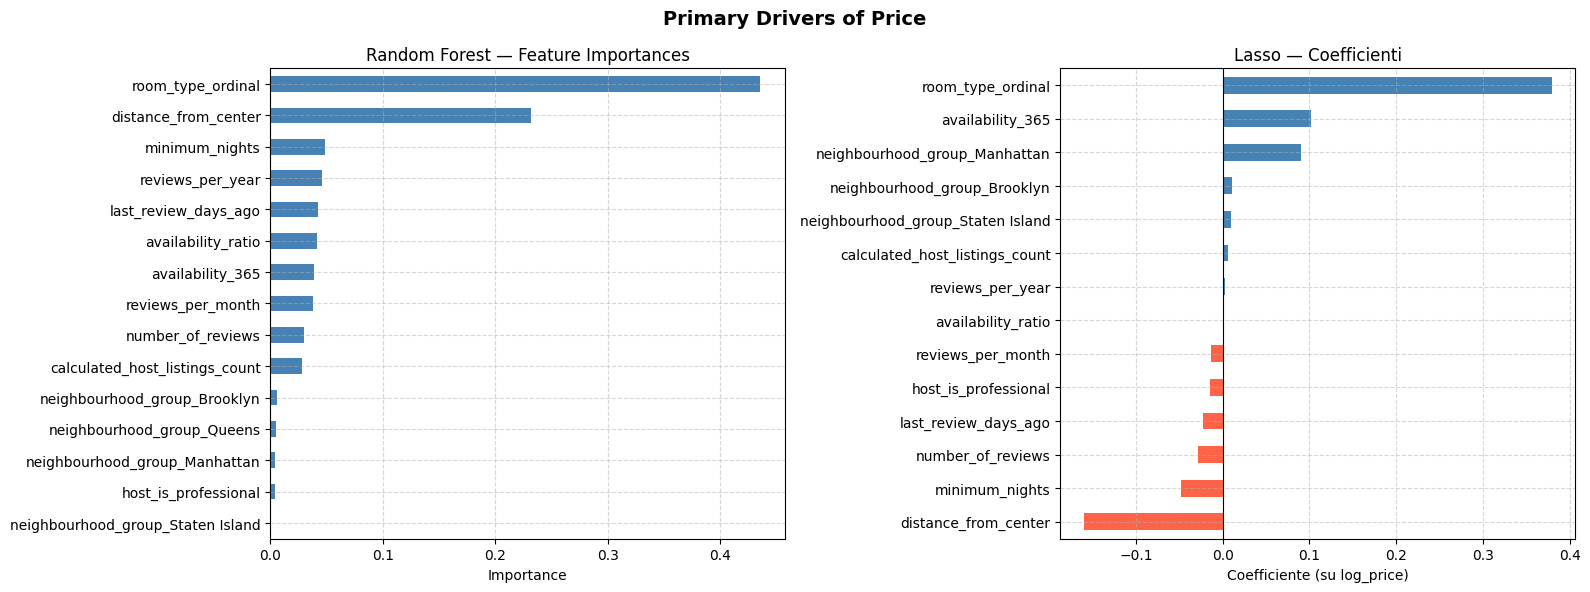

Calcolo della Validation Curve in corso...


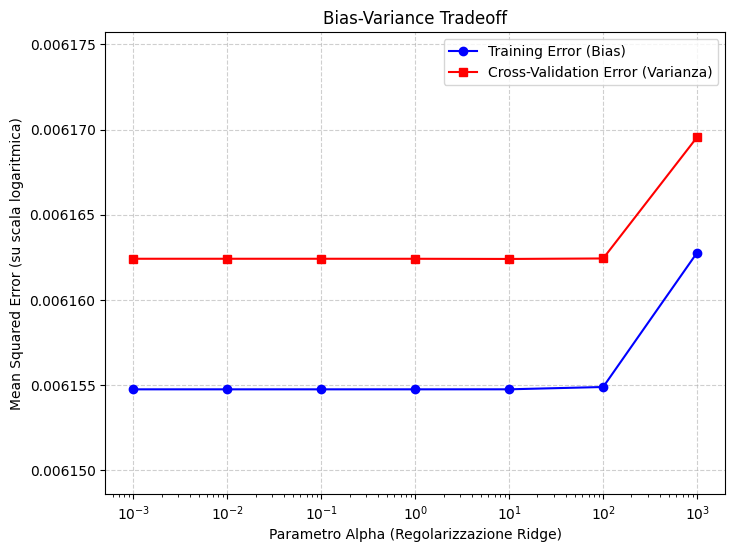

In [10]:
# OLS
metrics_ols = reg_linear.evaluate(model_type='linear', penalty=None)
print("OLS:  ", metrics_ols)

# Ridge
metrics_ridge = reg_linear.evaluate(model_type='linear', penalty='l2', alpha=1.0)
print("Ridge:", metrics_ridge)

# Lasso con feature selection
metrics_lasso = reg_linear.evaluate(model_type='linear', penalty='l1', alpha=0.01,
                                    use_feature_selection=True)
print("Lasso:", metrics_lasso)

# Random Forest
metrics_rf = reg_tree.evaluate(model_type='tree', n_estimators=100, max_depth=20)
print("RF:   ", metrics_rf)

# Feature Importance
reg_linear.plot_feature_importance()

# Bias-Variance Tradeoff
reg_linear.analyze_bias_variance()

# Slide Visualization

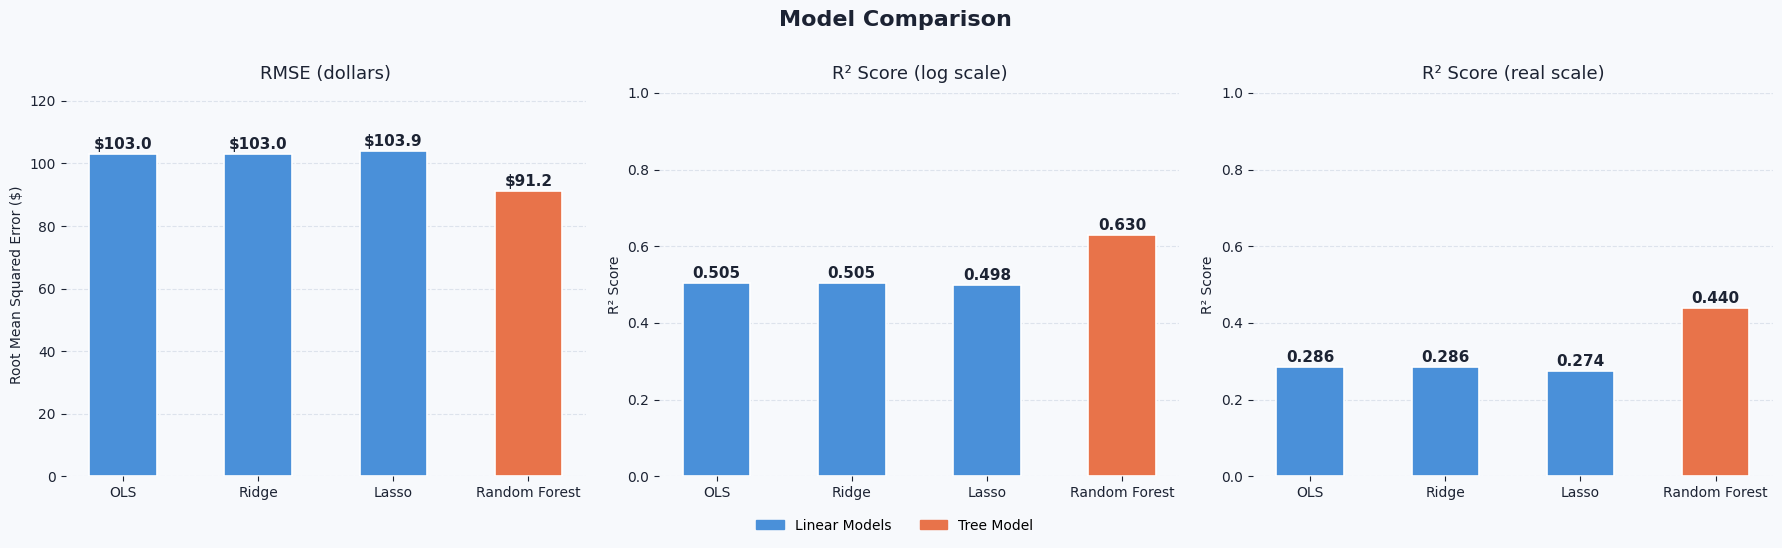

Salvato: slide_model_comparison.png


In [25]:
# ============================================================
# CELLA 1 — Model Comparison (RMSE & R²)
# ============================================================
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import numpy as np
 
# --- Inserisci qui i tuoi valori reali ---
models    = ['OLS', 'Ridge', 'Lasso', 'Random Forest']
rmse      = [103.02, 103.02, 103.89, 91.20]   # in dollari
r2_log    = [0.505,  0.505,  0.498,  0.630]   # R² su scala log (confrontabile con letteratura)
r2_dollars  = [0.286, 0.286, 0.274, 0.440]
 
PALETTE = {
    'linear': '#4A90D9',
    'tree':   '#E8734A',
    'bg':     '#F7F9FC',
    'grid':   '#DDE3EC',
    'text':   '#1C2333',
}
bar_colors = [PALETTE['linear'], PALETTE['linear'], PALETTE['linear'], PALETTE['tree']]
 
fig, axes = plt.subplots(1, 3, figsize=(18, 5), facecolor=PALETTE['bg'])
fig.suptitle('Model Comparison', fontsize=16, fontweight='bold',
             color=PALETTE['text'], y=1.01)
 
# — RMSE —
ax1 = axes[0]
ax1.set_facecolor(PALETTE['bg'])
bars = ax1.bar(models, rmse, color=bar_colors, width=0.5, zorder=3, edgecolor='white', linewidth=1.2)
for bar, val in zip(bars, rmse):
    ax1.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.8,
             f'${val:.1f}', ha='center', va='bottom', fontsize=11,
             fontweight='bold', color=PALETTE['text'])
ax1.set_title('RMSE (dollars)', fontsize=13, color=PALETTE['text'], pad=10)
ax1.set_ylabel('Root Mean Squared Error ($)', fontsize=10, color=PALETTE['text'])
ax1.set_ylim(0, max(rmse) * 1.18)
ax1.yaxis.grid(True, color=PALETTE['grid'], linestyle='--', linewidth=0.8, zorder=0)
ax1.set_axisbelow(True)
ax1.spines[['top','right','left','bottom']].set_visible(False)
ax1.tick_params(colors=PALETTE['text'])
 
# — R² log —
ax2 = axes[1]
ax2.set_facecolor(PALETTE['bg'])
bars2 = ax2.bar(models, r2_log, color=bar_colors, width=0.5, zorder=3, edgecolor='white', linewidth=1.2)
for bar, val in zip(bars2, r2_log):
    ax2.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.005,
             f'{val:.3f}', ha='center', va='bottom', fontsize=11,
             fontweight='bold', color=PALETTE['text'])
ax2.set_title('R² Score (log scale)', fontsize=13, color=PALETTE['text'], pad=10)
ax2.set_ylabel('R² Score', fontsize=10, color=PALETTE['text'])
ax2.set_ylim(0, 1.0)
ax2.axhline(1.0, color=PALETTE['grid'], linestyle='--', linewidth=0.8)
ax2.yaxis.grid(True, color=PALETTE['grid'], linestyle='--', linewidth=0.8, zorder=0)
ax2.set_axisbelow(True)
ax2.spines[['top','right','left','bottom']].set_visible(False)
ax2.tick_params(colors=PALETTE['text'])

# — R² real—
ax3 = axes[2]
ax3.set_facecolor(PALETTE['bg'])
bars3 = ax3.bar(models, r2_dollars, color=bar_colors, width=0.5, zorder=3, edgecolor='white', linewidth=1.2)
for bar, val in zip(bars3, r2_dollars):
    ax3.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.005,
             f'{val:.3f}', ha='center', va='bottom', fontsize=11,
             fontweight='bold', color=PALETTE['text'])
ax3.set_title('R² Score (real scale)', fontsize=13, color=PALETTE['text'], pad=10)
ax3.set_ylabel('R² Score', fontsize=10, color=PALETTE['text'])
ax3.set_ylim(0, 1.0)
ax3.axhline(1.0, color=PALETTE['grid'], linestyle='--', linewidth=0.8)
ax3.yaxis.grid(True, color=PALETTE['grid'], linestyle='--', linewidth=0.8, zorder=0)
ax3.set_axisbelow(True)
ax3.spines[['top','right','left','bottom']].set_visible(False)
ax3.tick_params(colors=PALETTE['text'])
 
# Legenda
patch_l = mpatches.Patch(color=PALETTE['linear'], label='Linear Models')
patch_t = mpatches.Patch(color=PALETTE['tree'],   label='Tree Model')
fig.legend(handles=[patch_l, patch_t], loc='lower center', ncol=2,
           frameon=False, fontsize=10, bbox_to_anchor=(0.5, -0.06))
 
plt.tight_layout()
plt.savefig('slide_model_comparison.png', dpi=180, bbox_inches='tight',
            facecolor=PALETTE['bg'])
plt.show()
print("Salvato: slide_model_comparison.png")
 

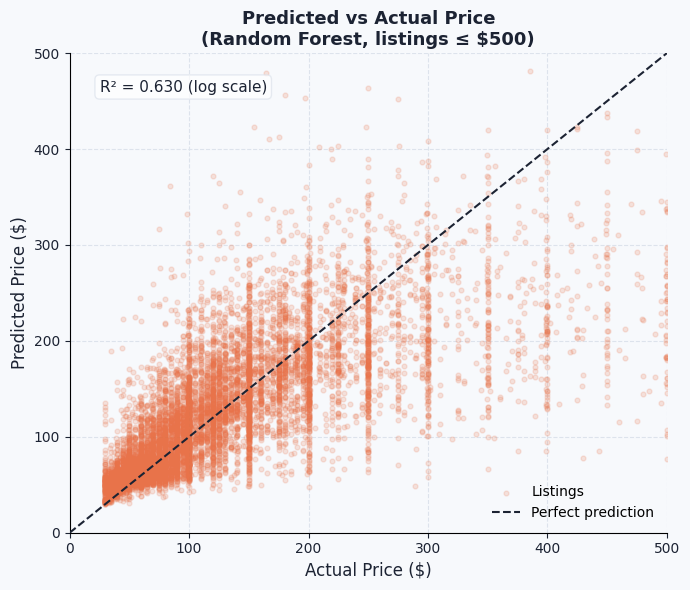

Salvato: slide_predicted_vs_actual.png


In [12]:
# ============================================================
# CELLA 2 — Predicted vs Actual (scatter)
# Richiede: y_test_tree, y_pred_log_tree (dalla cella TreePipeline)
# ============================================================
 
y_test_plot = np.expm1(y_test_tree)        # valori reali in $
y_pred_plot = np.expm1(y_pred_log_tree)    # predizioni in $
 
# Clip per leggibilità (rimuove outlier estremi dal grafico, NON dai dati)
clip = 500
mask = (y_test_plot <= clip) & (y_pred_plot <= clip)
yt, yp = y_test_plot[mask], y_pred_plot[mask]
 
fig, ax = plt.subplots(figsize=(7, 6), facecolor=PALETTE['bg'])
ax.set_facecolor(PALETTE['bg'])
 
ax.scatter(yt, yp, alpha=0.18, s=12, color=PALETTE['tree'], zorder=2, label='Listings')
ax.plot([0, clip], [0, clip], color='#1C2333', linewidth=1.5,
        linestyle='--', zorder=3, label='Perfect prediction')
 
ax.set_xlabel('Actual Price ($)', fontsize=12, color=PALETTE['text'])
ax.set_ylabel('Predicted Price ($)', fontsize=12, color=PALETTE['text'])
ax.set_title('Predicted vs Actual Price\n(Random Forest, listings ≤ $500)',
             fontsize=13, fontweight='bold', color=PALETTE['text'])
ax.set_xlim(0, clip); ax.set_ylim(0, clip)
ax.yaxis.grid(True, color=PALETTE['grid'], linestyle='--', linewidth=0.8)
ax.xaxis.grid(True, color=PALETTE['grid'], linestyle='--', linewidth=0.8)
ax.set_axisbelow(True)
ax.spines[['top','right']].set_visible(False)
ax.tick_params(colors=PALETTE['text'])
ax.legend(frameon=False, fontsize=10)
 
# Annotazione R²
ax.text(0.05, 0.92, f'R² = 0.630 (log scale)', transform=ax.transAxes,
        fontsize=11, color=PALETTE['text'],
        bbox=dict(boxstyle='round,pad=0.3', facecolor='white', alpha=0.7, edgecolor=PALETTE['grid']))
 
plt.tight_layout()
plt.savefig('slide_predicted_vs_actual.png', dpi=180, bbox_inches='tight',
            facecolor=PALETTE['bg'])
plt.show()
print("Salvato: slide_predicted_vs_actual.png")
 

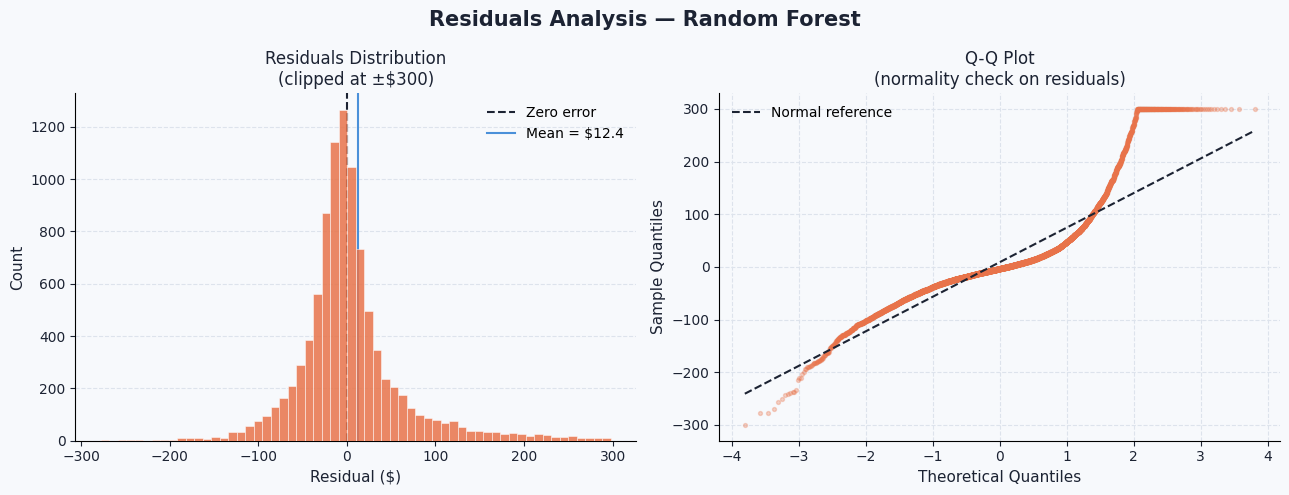

Salvato: slide_residuals.png


In [27]:
# ============================================================
# CELLA 3 — Residuals Distribution
# Richiede: y_test_tree, y_pred_log_tree
# ============================================================
from scipy import stats
 
residuals = y_test_plot - y_pred_plot  # residui in dollari, tutti i dati
 
fig, axes = plt.subplots(1, 2, figsize=(13, 5), facecolor=PALETTE['bg'])
fig.suptitle('Residuals Analysis — Random Forest', fontsize=15,
             fontweight='bold', color=PALETTE['text'])
 
# — Istogramma residui —
ax1 = axes[0]
ax1.set_facecolor(PALETTE['bg'])
residuals_filtered = residuals[(residuals >= -300) & (residuals <= 300)]
ax1.hist(residuals_filtered, bins=60,color=PALETTE['tree'],
         edgecolor='white', linewidth=0.4, zorder=3, alpha=0.85)
ax1.axvline(0, color='#1C2333', linewidth=1.5, linestyle='--', label='Zero error')
ax1.axvline(residuals.mean(), color=PALETTE['linear'], linewidth=1.5,
            linestyle='-', label=f'Mean = ${residuals.mean():.1f}')
ax1.set_xlabel('Residual ($)', fontsize=11, color=PALETTE['text'])
ax1.set_ylabel('Count', fontsize=11, color=PALETTE['text'])
ax1.set_title('Residuals Distribution\n(clipped at ±$300)', fontsize=12, color=PALETTE['text'])
ax1.yaxis.grid(True, color=PALETTE['grid'], linestyle='--', linewidth=0.8, zorder=0)
ax1.set_axisbelow(True)
ax1.spines[['top','right']].set_visible(False)
ax1.tick_params(colors=PALETTE['text'])
ax1.legend(frameon=False, fontsize=10)
 
# — Q-Q plot —
ax2 = axes[1]
ax2.set_facecolor(PALETTE['bg'])
res_clipped = residuals.clip(-300, 300)
(osm, osr), (slope, intercept, r) = stats.probplot(res_clipped, dist="norm")
ax2.scatter(osm, osr, color=PALETTE['tree'], alpha=0.3, s=8, zorder=2)
ax2.plot(osm, slope * np.array(osm) + intercept,
         color='#1C2333', linewidth=1.5, linestyle='--', zorder=3, label='Normal reference')
ax2.set_xlabel('Theoretical Quantiles', fontsize=11, color=PALETTE['text'])
ax2.set_ylabel('Sample Quantiles', fontsize=11, color=PALETTE['text'])
ax2.set_title('Q-Q Plot\n(normality check on residuals)', fontsize=12, color=PALETTE['text'])
ax2.yaxis.grid(True, color=PALETTE['grid'], linestyle='--', linewidth=0.8, zorder=0)
ax2.xaxis.grid(True, color=PALETTE['grid'], linestyle='--', linewidth=0.8, zorder=0)
ax2.set_axisbelow(True)
ax2.spines[['top','right']].set_visible(False)
ax2.tick_params(colors=PALETTE['text'])
ax2.legend(frameon=False, fontsize=10)
 
plt.tight_layout()
plt.savefig('slide_residuals.png', dpi=180, bbox_inches='tight',
            facecolor=PALETTE['bg'])
plt.show()
print("Salvato: slide_residuals.png")
 

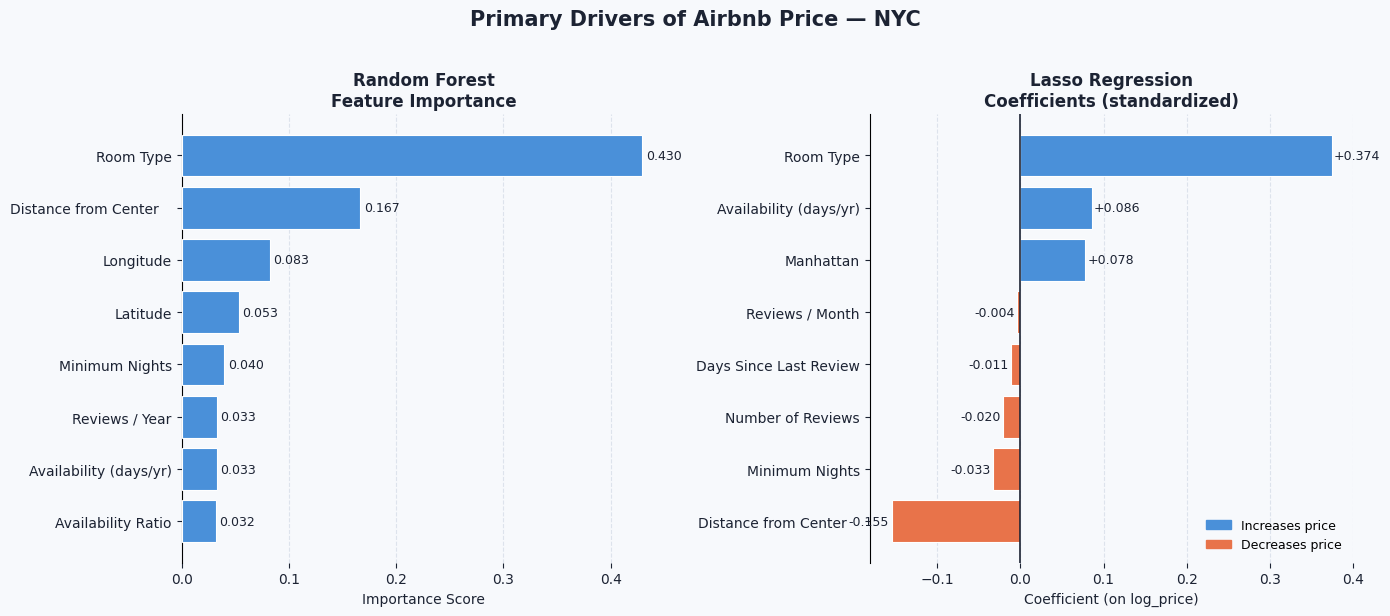

Salvato: slide_feature_importance.png


In [20]:
# ============================================================
# CELLA 4 — Feature Importance (slide version)
# Richiede: importanza_tree (dalla cella TreePipeline)
#           driver_attivi  (dalla cella LinearRegression/Lasso)
# ============================================================
 
# Rinominiamo le feature per le slide (più leggibili)
RENAME = {
    'room_type_ordinal':           'Room Type',
    'distance_from_center':        'Distance from Center   ',
    'latitude':                    'Latitude',
    'longitude':                   'Longitude',
    'minimum_nights':              'Minimum Nights',
    'reviews_per_year':            'Reviews / Year',
    'availability_365':            'Availability (days/yr)',
    'last_review_days_ago':        'Days Since Last Review',
    'number_of_reviews':           'Number of Reviews',
    'reviews_per_month':           'Reviews / Month',
    'calculated_host_listings_count': 'Host Listings Count',
    'host_is_professional':        'Professional Host',
    'availability_ratio':          'Availability Ratio',
    'neighbourhood_group_Manhattan': 'Manhattan',
    'neighbourhood_group_Brooklyn':  'Brooklyn',
    'neighbourhood_group_Queens':    'Queens',
    'neighbourhood_group_Staten Island': 'Staten Island',
    'neighbourhood_group_Bronx':     'Bronx',
}
 
# Top 8 RF
top_rf = importanza_tree.head(8).copy()
top_rf['Feature'] = top_rf['Feature'].map(lambda x: RENAME.get(x, x))
 
# Top 8 Lasso (per valore assoluto, già in driver_attivi)
top_lasso = driver_attivi.head(8).copy()
top_lasso['Feature'] = top_lasso['Feature'].map(lambda x: RENAME.get(x, x))
lasso_colors = [PALETTE['tree'] if v < 0 else PALETTE['linear']
                for v in top_lasso['Coefficiente'].sort_values()]
 
fig, axes = plt.subplots(1, 2, figsize=(14, 6), facecolor=PALETTE['bg'])
fig.suptitle('Primary Drivers of Airbnb Price — NYC',
             fontsize=15, fontweight='bold', color=PALETTE['text'], y=1.02)

 
# — RF importance —
ax1 = axes[0]
ax1.set_facecolor(PALETTE['bg'])
sorted_rf = top_rf.sort_values('Importanza')
bars = ax1.barh(sorted_rf['Feature'], sorted_rf['Importanza'],
                color=PALETTE['linear'], edgecolor='white', linewidth=0.8, zorder=3)
for bar, val in zip(bars, sorted_rf['Importanza']):
    ax1.text(val + 0.003, bar.get_y() + bar.get_height()/2,
             f'{val:.3f}', va='center', fontsize=9, color=PALETTE['text'])
ax1.set_title('Random Forest\nFeature Importance', fontsize=12,
              color=PALETTE['text'], fontweight='bold')
ax1.set_xlabel('Importance Score', fontsize=10, color=PALETTE['text'])
ax1.xaxis.grid(True, color=PALETTE['grid'], linestyle='--', linewidth=0.8, zorder=0)
ax1.set_axisbelow(True)
ax1.spines[['top','right','bottom']].set_visible(False)
ax1.tick_params(colors=PALETTE['text'], labelsize=10)
 
# — Lasso coefficients —
ax2 = axes[1]
ax2.set_facecolor(PALETTE['bg'])
sorted_lasso = top_lasso.sort_values('Coefficiente')
ax2.barh(sorted_lasso['Feature'], sorted_lasso['Coefficiente'],
         color=lasso_colors, edgecolor='white', linewidth=0.8, zorder=3)
ax2.axvline(0, color='#1C2333', linewidth=1.2, zorder=4)
for i, (val, feat) in enumerate(zip(sorted_lasso['Coefficiente'], sorted_lasso['Feature'])):
    offset = 0.003 if val >= 0 else -0.003
    ha = 'left' if val >= 0 else 'right'
    ax2.text(val + offset, i, f'{val:+.3f}', va='center',
             fontsize=9, color=PALETTE['text'], ha=ha)
ax2.set_title('Lasso Regression\nCoefficients (standardized)', fontsize=12,
              color=PALETTE['text'], fontweight='bold')
ax2.set_xlabel('Coefficient (on log_price)', fontsize=10, color=PALETTE['text'])
ax2.xaxis.grid(True, color=PALETTE['grid'], linestyle='--', linewidth=0.8, zorder=0)
ax2.set_axisbelow(True)
ax2.spines[['top','right','bottom']].set_visible(False)
ax2.tick_params(colors=PALETTE['text'], labelsize=10)
 
pos_patch = mpatches.Patch(color=PALETTE['linear'], label='Increases price')
neg_patch = mpatches.Patch(color=PALETTE['tree'],   label='Decreases price')
ax2.legend(handles=[pos_patch, neg_patch], frameon=False, fontsize=9,
           loc='lower right')

 
plt.tight_layout()
plt.savefig('slide_feature_importance.png', dpi=180, bbox_inches='tight',
            facecolor=PALETTE['bg'])
plt.show()
print("Salvato: slide_feature_importance.png")